# Adversarial Search: Playing Dots and Boxes


## Instructions

Total Points: Undegraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play the game Dots and Boxes:

> "Dots and Boxes is a pencil-and-paper game for two players. The game starts with an empty grid of dots. Usually two players take turns adding a single horizontal or vertical line between two unjoined adjacent dots. A player who completes the fourth side of a 1x1 box earns one point and takes another turn. A point is typically recorded by placing a mark that identifies the player in the box, such as an initial. The game ends when no more lines can be placed. The winner is the player with the most points. The board may be of any size grid." (see [Dots and Boxes on Wikipedia](https://en.wikipedia.org/wiki/Dots_and_Boxes))

You can play Dots and Boxes [here](https://www.math.ucla.edu/~tom/Games/dots&boxes.html).

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
print("""
1. Initial State (Trạng thái ban đầu):
   - Lưới gồm (R x C) điểm chấm (tương ứng m = R-1 hàng và n = C-1 cột ô vuông).
   - Ban đầu chưa có cạnh nào được nối (lines = {}) và chưa có ô nào được đóng (boxes = {}).
   - Người chơi 1 (+1) đi trước.

2. Actions (Hành động hợp lệ):
   - Chọn 1 cạnh chưa được vẽ:
     + Cạnh ngang ('h', r, c) với 0 <= r < R, 0 <= c < C - 1
     + Cạnh dọc ('v', r, c) với 0 <= r < R - 1, 0 <= c < C

3. Transition Model - result(s, player, a) (Mô hình chuyển trạng thái):
   - Thêm cạnh a vào tập lines.
   - Nếu cạnh vừa nối hoàn thành cạnh thứ 4 của 1 hoặc 2 ô vuông 1x1:
     + Ghi nhận ô vuông đó thuộc về player (+1 hoặc -1).
     + QUAN TRỌNG: player ĐƯỢC ĐI TIẾP một lượt nữa.
   - Ngược lại, chuyển lượt sang đối thủ (-player).

4. Terminal State Test - terminal(s) (Kiểm tra kết thúc):
   - Trò chơi kết thúc khi toàn bộ E = 2*m*n + m + n cạnh đã được vẽ hết (tức toàn bộ m*n ô vuông đều có chủ).

5. Utility (Hàm tiện ích ở trạng thái kết thúc):
   - Từ góc nhìn của player (+1 hoặc -1):
     + Thắng (số ô của player > đối thủ): +1
     + Thua (số ô của player < đối thủ): -1
     + Hòa (số ô bằng nhau): 0
""")


1. Initial State (Trạng thái ban đầu):
   - Lưới gồm (R x C) điểm chấm (tương ứng m = R-1 hàng và n = C-1 cột ô vuông).
   - Ban đầu chưa có cạnh nào được nối (lines = {}) và chưa có ô nào được đóng (boxes = {}).
   - Người chơi 1 (+1) đi trước.

2. Actions (Hành động hợp lệ):
   - Chọn 1 cạnh chưa được vẽ:
     + Cạnh ngang ('h', r, c) với 0 <= r < R, 0 <= c < C - 1
     + Cạnh dọc ('v', r, c) với 0 <= r < R - 1, 0 <= c < C

3. Transition Model - result(s, player, a) (Mô hình chuyển trạng thái):
   - Thêm cạnh a vào tập lines.
   - Nếu cạnh vừa nối hoàn thành cạnh thứ 4 của 1 hoặc 2 ô vuông 1x1:
     + Ghi nhận ô vuông đó thuộc về player (+1 hoặc -1).
     + QUAN TRỌNG: player ĐƯỢC ĐI TIẾP một lượt nữa.
   - Ngược lại, chuyển lượt sang đối thủ (-player).

4. Terminal State Test - terminal(s) (Kiểm tra kết thúc):
   - Trò chơi kết thúc khi toàn bộ E = 2*m*n + m + n cạnh đã được vẽ hết (tức toàn bộ m*n ô vuông đều có chủ).

5. Utility (Hàm tiện ích ở trạng thái kết thúc):
   - Từ góc n

How big is the state space? Give an estimate and explain it.

In [2]:
import math

def edges_count(m, n):
    """Số cạnh trên lưới m x n ô vuông (tương ứng (m+1) x (n+1) chấm)."""
    return 2 * m * n + m + n

for m, n in [(2, 2), (3, 3), (5, 5)]:
    E = edges_count(m, n)
    # Ước lượng cận trên không gian trạng thái:
    # - Mỗi cạnh có 2 trạng thái (đã vẽ / chưa vẽ) -> 2^E cấu hình đường kẻ
    # - Mỗi ô vuông có 3 trạng thái (chưa đóng, +1, -1), nhưng thực tế các ô phụ thuộc đường kẻ.
    print(f"Lưới {m}x{n} ô ({m+1}x{n+1} chấm): E = {E} cạnh -> Số cấu hình cạnh = 2^{E} = {2**E:,}")

Lưới 2x2 ô (3x3 chấm): E = 12 cạnh -> Số cấu hình cạnh = 2^12 = 4,096
Lưới 3x3 ô (4x4 chấm): E = 24 cạnh -> Số cấu hình cạnh = 2^24 = 16,777,216
Lưới 5x5 ô (6x6 chấm): E = 60 cạnh -> Số cấu hình cạnh = 2^60 = 1,152,921,504,606,846,976


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
for m, n in [(2, 2), (3, 3), (5, 5)]:
    E = edges_count(m, n)
    # Ở bước đầu tiên có E lựa chọn, bước 2 có E-1, ..., tổng độ sâu đúng bằng E
    # => Kích thước cây trò chơi đầy đủ là E! (giai thừa)
    print(f"Lưới {m}x{n} ô (E = {E} cạnh): Kích thước cây trò chơi = {E}! = {math.factorial(E):.3e} nút")

Lưới 2x2 ô (E = 12 cạnh): Kích thước cây trò chơi = 12! = 4.790e+08 nút
Lưới 3x3 ô (E = 24 cạnh): Kích thước cây trò chơi = 24! = 6.204e+23 nút
Lưới 5x5 ô (E = 60 cạnh): Kích thước cây trò chơi = 60! = 8.321e+81 nút


## Task 2: Game Environment and Random Agent [30 point]

You need to think about a data structure to represent the board meaning he placed lines and who finished what box. There are many options. Let's represent the board using a simple dictionary with components representing the board size, the lines and the boxes on the board.

**Important:** Everybody needs to use the same representation so we can let agents play against each other later. 

In [5]:
board = {
    'size': (4, 4),  ### number of rows and columns of dots
    'lines': dict(), ### keys are the set of drawn lines
    'boxes': dict    ### keys are the boxes and the value is the player who completed each box
}

def draw_line(board, orientation, row, col):
    """
    Place a line on an exiting board.
       
    Parameters
    ----------
    board: dict
        the board
    orientation: str
        either 'h' or 'v' for horizontal or vertical
    row, col: int
        index of the starting dot for the line (starting with 0)
    
    """
    
    if orientation not in ['h', 'v']:
        return False
        
    if row < 0 or col < 0:
        return False
        
    if row >= board['size'][0] + (orientation == 'v') or col >= board['size'][1] + (orientation == 'h'):
        return False
        
    if (orientation, row, col) in board['lines']:
        return False
            
    board["lines"][(orientation, row, col)] = True
    return True
    

print(draw_line(board, "h", 1, 1))
print(draw_line(board, "v", 1, 1))

# this should not work
print(draw_line(board, "h", 1, 1))

board

True
True
False


{'size': (4, 4),
 'lines': {('h', 1, 1): True, ('v', 1, 1): True},
 'boxes': dict}

Write code to display the board. **Bonus point: Post your visualization code with an example output to the discussion board. The best visualization will earn you bonus participation points in this class.**

In [6]:
import matplotlib.pyplot as plt

def empty_board(size=(4, 4)):
    """Tạo bàn cờ rỗng chuẩn với size = (số hàng chấm, số cột chấm).
    Ví dụ: size=(3, 3) là lưới 2x2 ô; size=(4, 4) là lưới 3x3 ô."""
    return {
        'size': size,
        'lines': dict(),
        'boxes': dict()
    }

def show_board(board, figsize=(4, 4)):
    """Hiển thị bàn cờ Dots and Boxes trực quan bằng Matplotlib."""
    R, C = board['size']
    fig, ax = plt.subplots(figsize=figsize)

    # Vẽ các cạnh đã nối
    for (ori, r, c) in board['lines']:
        if ori == 'h':
            ax.plot([c, c + 1], [R - 1 - r, R - 1 - r], color='navy', linewidth=3)
        else:
            ax.plot([c, c], [R - 1 - r, R - 1 - (r + 1)], color='navy', linewidth=3)

    # Tô màu & ghi tên người sở hữu ô đã đóng
    boxes = board['boxes'] if isinstance(board['boxes'], dict) else {}
    for (r, c), owner in boxes.items():
        color = '#ffcccc' if owner == 1 else '#cce5ff'
        label = 'P1' if owner == 1 else 'P2'
        text_color = 'red' if owner == 1 else 'blue'
        rect = plt.Rectangle((c + 0.08, R - 1 - (r + 1) + 0.08), 0.84, 0.84, color=color, alpha=0.7)
        ax.add_patch(rect)
        ax.text(c + 0.5, R - 1 - r - 0.5, label, ha='center', va='center',
                fontsize=12, fontweight='bold', color=text_color)

    # Vẽ các chấm (dots)
    xs = [c for r in range(R) for c in range(C)]
    ys = [R - 1 - r for r in range(R) for c in range(C)]
    ax.scatter(xs, ys, color='black', s=60, zorder=5)

    ax.set_xlim(-0.3, C - 0.7)
    ax.set_ylim(-0.3, R - 0.7)
    ax.set_aspect('equal')
    ax.axis('off')
    plt.show()

# Kiểm tra hiển thị minh họa
demo = empty_board((4, 4))

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

__Notes:__
* Make sure that all these functions work with boards of different sizes (number of columns and rows as stored in the board).
* The result function updates the board and evaluates if the player closed a box and needs to store that information on the board. Add elements of the form `(row,col): player` to the board dictionary. `row` and `col` are the coordinates for the box and `player` is +1 or -1 representing the player. For example `(0,0): -1` means that the top-left box belongs to the other player. 
* _Important:_ Remember that a player goes again after she completes a box!

In [7]:
def actions(board):
    """Trả về danh sách toàn bộ các cạnh hợp lệ còn trống."""
    R, C = board['size']
    acts = []
    for r in range(R):
        for c in range(C - 1):
            if ('h', r, c) not in board['lines']:
                acts.append(('h', r, c))
    for r in range(R - 1):
        for c in range(C):
            if ('v', r, c) not in board['lines']:
                acts.append(('v', r, c))
    return acts

def _is_box_closed(lines, r, c):
    """Kiểm tra ô vuông (r, c) đã có đủ 4 cạnh xung quanh chưa."""
    return (
        ('h', r, c) in lines and
        ('h', r + 1, c) in lines and
        ('v', r, c) in lines and
        ('v', r, c + 1) in lines
    )

def result(board, player, action):
    """Thực hiện nước đi action trên bản sao bàn cờ và cập nhật ô vuông vừa đóng (nếu có)."""
    if action in board['lines']:
        raise ValueError(f"Illegal action {action}!")

    new_board = {
        'size': board['size'],
        'lines': board['lines'].copy(),
        'boxes': board['boxes'].copy() if isinstance(board['boxes'], dict) else {}
    }
    new_board['lines'][action] = True

    R, C = new_board['size']
    ori, r, c = action
    candidates = []
    if ori == 'h':
        if r > 0: candidates.append((r - 1, c))
        if r < R - 1: candidates.append((r, c))
    else:
        if c > 0: candidates.append((r, c - 1))
        if c < C - 1: candidates.append((r, c))

    for br, bc in candidates:
        if (br, bc) not in new_board['boxes'] and _is_box_closed(new_board['lines'], br, bc):
            new_board['boxes'][(br, bc)] = player

    return new_board

def terminal(board):
    """Kiểm tra ván đấu đã kết thúc chưa (tất cả ô vuông đã có chủ)."""
    R, C = board['size']
    return len(board['boxes']) == (R - 1) * (C - 1)

def utility(board, player=1):
    """Trả về +1 (thắng), -1 (thua), 0 (hòa) cho player; hoặc None nếu chưa kết thúc."""
    if not terminal(board):
        return None
    diff = player * sum(board['boxes'].values())
    if diff > 0: return 1
    if diff < 0: return -1
    return 0

# Kiểm tra nhanh các hàm trên bàn 3x3 chấm (2x2 ô)
test_b = empty_board((3, 3))
print("Số nước đi ban đầu trên lưới 2x2 ô:", len(actions(test_b)))  # kỳ vọng: 12
test_b = result(test_b, 1, ('h', 0, 0))
test_b = result(test_b, -1, ('h', 1, 0))
test_b = result(test_b, 1, ('v', 0, 0))
test_b = result(test_b, -1, ('v', 0, 1))  # P2 (-1) đóng ô (0,0)
print("Ô đã đóng sau nước thứ 4:", test_b['boxes'])  # kỳ vọng: {(0, 0): -1}

Số nước đi ban đầu trên lưới 2x2 ô: 12
Ô đã đóng sau nước thứ 4: {(0, 0): -1}


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on by the environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [8]:
import random

def random_player(board, player=None):
    """Tác tử chọn ngẫu nhiên một cạnh hợp lệ trên bàn cờ."""
    return random.choice(actions(board))

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [9]:
import time

def play(p1, p2, size=(4, 4), N=1000, show_final_board=False):
    """Cho p1 (+1) và p2 (-1) đấu N ván trên bàn cờ kích thước size."""
    results = {1: 0, -1: 0, 0: 0}  # 1: P1 thắng, -1: P2 thắng, 0: Hòa

    for _ in range(N):
        board = empty_board(size)
        current_player = 1

        while not terminal(board):
            agent = p1 if current_player == 1 else p2
            move = agent(board, current_player)
            prev_boxes = len(board['boxes'])
            board = result(board, current_player, move)

            # Đóng được ít nhất 1 ô -> giữ nguyên lượt (đi tiếp), ngược lại đổi lượt
            if len(board['boxes']) == prev_boxes:
                current_player = -current_player

        u = utility(board, player=1)
        results[u] += 1
        if show_final_board:
            show_board(board)

    return results

random.seed(42)
t0 = time.perf_counter()
res_random = play(random_player, random_player, size=(4, 4), N=1000)
elapsed = time.perf_counter() - t0

print(f"Random vs Random (1000 ván, lưới 3x3 ô / 4x4 chấm): {res_random} | Thời gian: {elapsed:.2f} s")
print(f"Tỷ lệ: P1 (+1) thắng {res_random[1]/10:.1f}% | P2 (-1) thắng {res_random[-1]/10:.1f}% | Hòa {res_random[0]/10:.1f}%")

Random vs Random (1000 ván, lưới 3x3 ô / 4x4 chấm): {1: 477, -1: 523, 0: 0} | Thời gian: 0.10 s
Tỷ lệ: P1 (+1) thắng 47.7% | P2 (-1) thắng 52.3% | Hòa 0.0%


## Task 3: Minimax Search with Alpha-Beta Pruning [30 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for larger board may be too large. You can experiment with smaller boards.
* Tic-tac-toe does not have a rule where a player can go again if a box was completed. You need to adapt the tree search to reflect that rule.

In [10]:
def _box_sides_count(lines, r, c):
    """Đếm số cạnh đã vẽ xung quanh ô (r, c)."""
    return (
        (('h', r, c) in lines) +
        (('h', r + 1, c) in lines) +
        (('v', r, c) in lines) +
        (('v', r, c + 1) in lines)
    )

def alpha_beta_search(board, player=1, action_fn=None):
    """
    Minimax kết hợp cắt tỉa Alpha-Beta cho Dots and Boxes.
    Thích ứng với luật: đóng được ô thì giữ nguyên lượt (MAX đi tiếp MAX, hoặc MIN đi tiếp MIN).
    """
    if action_fn is None:
        action_fn = actions

    nodes = [0]

    def alphabeta(b, turn, alpha, beta):
        nodes[0] += 1
        if terminal(b):
            return utility(b, player=player), None

        acts = action_fn(b)
        best_move = acts[0]

        if turn == player:  # Nút MAX
            v = -float('inf')
            for a in acts:
                nb = result(b, turn, a)
                scored = len(nb['boxes']) > len(b['boxes'])
                next_turn = turn if scored else -turn
                val, _ = alphabeta(nb, next_turn, alpha, beta)
                if val > v:
                    v, best_move = val, a
                alpha = max(alpha, v)
                if v >= beta:
                    break
            return v, best_move
        else:               # Nút MIN
            v = float('inf')
            for a in acts:
                nb = result(b, turn, a)
                scored = len(nb['boxes']) > len(b['boxes'])
                next_turn = turn if scored else -turn
                val, _ = alphabeta(nb, next_turn, alpha, beta)
                if val < v:
                    v, best_move = val, a
                beta = min(beta, v)
                if v <= alpha:
                    break
            return v, best_move

    best_val, best_move = alphabeta(board, player, -float('inf'), float('inf'))
    return {'move': best_move, 'value': best_val, 'nodes': nodes[0]}

def alpha_beta_player(board, player=1):
    """Agent sử dụng Alpha-Beta Pruning (chuẩn signature giống random_player)."""
    return alpha_beta_search(board, player=player)['move']

Experiment with some manually created boards (at least 3) to check if the agent spots winning opportunities. Discuss the results.

=== TEST 1: P1 có thể đóng ngay ô (0,0) bằng ('v', 0, 1) ===


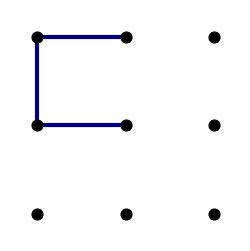

Kết quả: {'move': ('v', 0, 1), 'value': 0, 'nodes': 18110}

=== TEST 2: P1 tránh tạo ô 3 cạnh giúp đối thủ ăn chuỗi ===


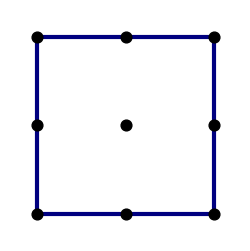

Kết quả: {'move': ('h', 1, 0), 'value': -1, 'nodes': 34}

=== TEST 3: P1 ăn liên hoàn 2 ô (0,0) -> (0,1) nhờ luật đi tiếp ===


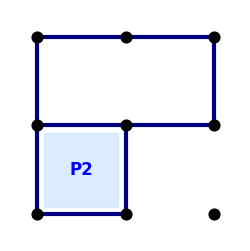

Kết quả: {'move': ('v', 0, 1), 'value': 0, 'nodes': 14}


In [11]:
# Test 1: P1 có cơ hội đóng ngay ô (0,0) để dẫn trước và thắng trên lưới 2x2 ô (3x3 chấm)
b_win = empty_board((3, 3))
for act in [('h', 0, 0), ('h', 1, 0), ('v', 0, 0)]:
    b_win['lines'][act] = True
print("=== TEST 1: P1 có thể đóng ngay ô (0,0) bằng ('v', 0, 1) ===")
show_board(b_win, figsize=(3, 3))
res1 = alpha_beta_search(b_win, player=1)
print("Kết quả:", res1)

# Test 2: P1 tránh mở cạnh thứ 3 của ô (0,0) (nước bẫy cho đối thủ ăn chuỗi)
b_trap = empty_board((3, 3))
for act in [('h', 0, 0), ('v', 0, 0), ('h', 0, 1), ('v', 0, 2),
            ('h', 2, 0), ('v', 1, 0), ('h', 2, 1), ('v', 1, 2)]:
    b_trap['lines'][act] = True
print("\n=== TEST 2: P1 tránh tạo ô 3 cạnh giúp đối thủ ăn chuỗi ===")
show_board(b_trap, figsize=(3, 3))
res2 = alpha_beta_search(b_trap, player=1)
print("Kết quả:", res2)

# Test 3: P1 ăn chuỗi liên hoàn 2 ô nhờ luật đóng ô được đi tiếp
b_chain = empty_board((3, 3))
for act in [('h', 0, 0), ('h', 1, 0), ('v', 0, 0),
            ('h', 0, 1), ('h', 1, 1), ('v', 0, 2),
            ('h', 2, 0), ('v', 1, 0), ('v', 1, 1)]:
    b_chain['lines'][act] = True
b_chain['boxes'][(1, 0)] = -1  # P2 đang có 1 ô
print("\n=== TEST 3: P1 ăn liên hoàn 2 ô (0,0) -> (0,1) nhờ luật đi tiếp ===")
show_board(b_chain, figsize=(3, 3))
res3 = alpha_beta_search(b_chain, player=1)
print("Kết quả:", res3)

How long does it take to make a move? Start with a smaller board make the board larger. What is the largest board you can solve?

In [12]:
import pandas as pd

size_benchmarks = []
# Lưu ý: size=(R, C) là số điểm chấm. (2,2)=1x1 ô (4 cạnh), (2,3)=1x2 ô (7 cạnh),
# (2,4)=1x3 ô (10 cạnh), (3,3)=2x2 ô (12 cạnh).
# Bàn (3,4) = 2x3 ô có E=17 cạnh (17! ≈ 3.55e14) quá lớn không thể duyệt cạn!
for sz in [(2, 2), (2, 3), (2, 4), (3, 3)]:
    b = empty_board(sz)
    E = len(actions(b))
    t0 = time.perf_counter()
    res = alpha_beta_search(b, player=1)
    dt_ms = (time.perf_counter() - t0) * 1000
    size_benchmarks.append({
        "Grid (dots)": f"{sz[0]}x{sz[1]}",
        "Boxes": f"{sz[0]-1}x{sz[1]-1}",
        "Edges (E)": E,
        "Best move": res['move'],
        "Value": res['value'],
        "Nodes": res['nodes'],
        "Time (ms)": round(dt_ms, 2)
    })

df_sizes = pd.DataFrame(size_benchmarks)
display(df_sizes)
print("=> Bàn cờ vuông lớn nhất Alpha-Beta duyệt cạn giải được từ bàn rỗng là 3x3 chấm (2x2 ô, E=12 cạnh).")

,Grid (dots),Boxes,Edges (E),Best move,Value,Nodes,Time (ms)
0,2x2,1x1,4,"(h, 0, 0)",-1,31,0.08
1,2x3,1x2,7,"(v, 0, 1)",0,1398,2.60
2,2x4,1x3,10,"(h, 0, 0)",-1,32097,82.87
3,3x3,2x2,12,"(h, 0, 0)",1,440722,1115.48


=> Bàn cờ vuông lớn nhất Alpha-Beta duyệt cạn giải được từ bàn rỗng là 3x3 chấm (2x2 ô, E=12 cạnh).


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. 

Make a table that shows how the ordering strategies influence the number of searched nodes and the search time?

In [13]:
def ordered_actions(board):
    """
    Sắp xếp nước đi ưu tiên cho Dots and Boxes:
    0: Nước đóng được ô ngay (cạnh của ô đang có 3 cạnh)
    1: Nước an toàn (không tạo ra ô có 3 cạnh cho đối thủ)
    2: Nước mở ô (tạo ra ô có 3 cạnh - bất đắc dĩ mới đi)
    """
    R, C = board['size']
    lines = board['lines']

    def priority(a):
        ori, r, c = a
        cands = []
        if ori == 'h':
            if r > 0: cands.append((r - 1, c))
            if r < R - 1: cands.append((r, c))
        else:
            if c > 0: cands.append((r, c - 1))
            if c < C - 1: cands.append((r, c))
        counts = [_box_sides_count(lines, br, bc) for br, bc in cands]
        if any(s == 3 for s in counts):
            return 0
        if any(s == 2 for s in counts):
            return 2
        return 1

    return sorted(actions(board), key=priority)

mo_compare = []
for sz in [(2, 3), (2, 4), (3, 3)]:
    b = empty_board(sz)
    t0 = time.perf_counter()
    r_no = alpha_beta_search(b, player=1, action_fn=actions)
    t_no = (time.perf_counter() - t0) * 1000

    t1 = time.perf_counter()
    r_yes = alpha_beta_search(b, player=1, action_fn=ordered_actions)
    t_yes = (time.perf_counter() - t1) * 1000

    reduction = (1 - r_yes['nodes'] / r_no['nodes']) * 100
    mo_compare.append({
        "Size (dots)": f"{sz[0]}x{sz[1]}",
        "Nodes (Mặc định)": r_no['nodes'],
        "Time (ms, Mặc định)": round(t_no, 2),
        "Nodes (Move Ordering)": r_yes['nodes'],
        "Time (ms, Move Ordering)": round(t_yes, 2),
        "Giảm số nút (%)": round(reduction, 2)
    })

display(pd.DataFrame(mo_compare))

,Size (dots),Nodes (Mặc định),"Time (ms, Mặc định)",Nodes (Move Ordering),"Time (ms, Move Ordering)",Giảm số nút (%)
0,2x3,1398,2.63,839,2.87,39.99
1,2x4,32097,67.04,11132,47.89,65.32
2,3x3,440722,1042.91,91033,407.93,79.34


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [14]:
# Giải pháp cho các nước đi đầu tiên trên bàn cờ rỗng (trường hợp tệ nhất):
# 1. Dùng Opening Cache / Bảng đối xứng: Ghi nhớ kết quả tính toán cho trạng thái rỗng
#    và các trạng thái đầu ván để không phải duyệt lại cây khổng lồ mỗi ván.
# 2. Kết hợp Move Ordering + Transposition Table (lưu cache theo tập lines đã vẽ).

OPENING_CACHE = {}

def fast_alpha_beta_player(board, player=1):
    """Alpha-Beta dùng Move Ordering + Cache nước khai cuộc (chỉ lưu khi còn ít cạnh)."""
    key = (board['size'], player, frozenset(board['lines'].keys()))
    if len(board['lines']) <= 2 and key in OPENING_CACHE:
        return OPENING_CACHE[key]

    move = alpha_beta_search(board, player=player, action_fn=ordered_actions)['move']
    if len(board['lines']) <= 2:
        OPENING_CACHE[key] = move
    return move

# Đo tốc độ nước đầu tiên lần 1 (chưa cache) vs lần 2 (đã cache) trên lưới 3x3 chấm
b_empty = empty_board((3, 3))
t0 = time.perf_counter()
m1 = fast_alpha_beta_player(b_empty, 1)
print(f"Lần 1 (tính đầy đủ): move={m1}, time={(time.perf_counter()-t0)*1000:.2f} ms")

t1 = time.perf_counter()
m2 = fast_alpha_beta_player(b_empty, 1)
print(f"Lần 2 (dùng Opening Cache): move={m2}, time={(time.perf_counter()-t1)*1000:.4f} ms")

Lần 1 (tính đầy đủ): move=('h', 0, 0), time=409.33 ms
Lần 2 (dùng Opening Cache): move=('h', 0, 0), time=0.0537 ms


### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [15]:
random.seed(42)

t0 = time.perf_counter()
res_ab_first = play(fast_alpha_beta_player, random_player, size=(3, 3), N=100)
t_first = time.perf_counter() - t0

t1 = time.perf_counter()
res_ab_second = play(random_player, fast_alpha_beta_player, size=(3, 3), N=100)
t_second = time.perf_counter() - t1

print(f"Alpha-Beta (P1 đi trước) vs Random (100 ván, 2x2 ô): {res_ab_first} | {t_first:.2f} s")
print(f"Random vs Alpha-Beta (P2 đi sau) (100 ván, 2x2 ô): {res_ab_second} | {t_second:.2f} s")

Alpha-Beta (P1 đi trước) vs Random (100 ván, 2x2 ô): {1: 100, -1: 0, 0: 0} | 0.79 s
Random vs Alpha-Beta (P2 đi sau) (100 ván, 2x2 ô): {1: 3, -1: 57, 0: 40} | 3.50 s


## Task 4: Heuristic Alpha-Beta Tree Search [30 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [16]:
def h_simple(board, player, turn):
    """Heuristic 1 (Đơn giản): Chỉ dựa vào chênh lệch số ô đã đóng hiện tại."""
    R, C = board['size']
    total_boxes = (R - 1) * (C - 1)
    box_diff = player * sum(board['boxes'].values())
    return box_diff / (total_boxes + 1)

def h_strategic(board, player, turn):
    """
    Heuristic 2 (Chiến thuật):
    - Chênh lệch số ô đã đóng (trọng số 10).
    - Số ô đang có 3 cạnh (cơ hội ăn ngay của người đang tới lượt `turn`, trọng số 4).
    - Số ô có 2 cạnh (ô nhạy cảm dễ mở chuỗi, trọng số nhỏ).
    """
    R, C = board['size']
    total_boxes = (R - 1) * (C - 1)
    box_diff = player * sum(board['boxes'].values())

    three_sides = 0
    two_sides = 0
    for r in range(R - 1):
        for c in range(C - 1):
            if (r, c) not in board['boxes']:
                cnt = _box_sides_count(board['lines'], r, c)
                if cnt == 3:
                    three_sides += 1
                elif cnt == 2:
                    two_sides += 1

    turn_sign = 1 if turn == player else -1
    raw_score = 10 * box_diff + turn_sign * (4 * three_sides) - turn_sign * (0.5 * two_sides)
    max_bound = 10 * total_boxes + 5 * total_boxes + 1
    return raw_score / max_bound

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [17]:
def heuristic_alpha_beta_search(board, player=1, cutoff=3, h_fn=h_strategic):
    """Alpha-Beta cắt tỉa theo độ sâu `cutoff` và dùng hàm đánh giá `h_fn`."""
    nodes = [0]

    def ab_cutoff(b, turn, depth, alpha, beta):
        nodes[0] += 1
        if terminal(b):
            return utility(b, player=player), None
        if depth >= cutoff:
            return h_fn(b, player, turn), None

        acts = ordered_actions(b)
        best_move = acts[0]

        if turn == player:  # MAX
            v = -float('inf')
            for a in acts:
                nb = result(b, turn, a)
                next_turn = turn if len(nb['boxes']) > len(b['boxes']) else -turn
                val, _ = ab_cutoff(nb, next_turn, depth + 1, alpha, beta)
                if val > v:
                    v, best_move = val, a
                alpha = max(alpha, v)
                if v >= beta:
                    break
            return v, best_move
        else:               # MIN
            v = float('inf')
            for a in acts:
                nb = result(b, turn, a)
                next_turn = turn if len(nb['boxes']) > len(b['boxes']) else -turn
                val, _ = ab_cutoff(nb, next_turn, depth + 1, alpha, beta)
                if val < v:
                    v, best_move = val, a
                beta = min(beta, v)
                if v <= alpha:
                    break
            return v, best_move

    val, move = ab_cutoff(board, player, 0, -float('inf'), float('inf'))
    return {'move': move, 'value': round(val, 4), 'nodes': nodes[0]}

# Thử nghiệm các giá trị cutoff = 2, 3, 4 trên bàn cờ 4x4 chấm (3x3 ô)
b_test = empty_board((4, 4))
cutoff_exp = []
for d in [2, 3, 4]:
    t0 = time.perf_counter()
    res = heuristic_alpha_beta_search(b_test, player=1, cutoff=d, h_fn=h_strategic)
    dt_ms = (time.perf_counter() - t0) * 1000
    cutoff_exp.append({
        "Board (dots)": "4x4 (3x3 ô)",
        "Cutoff": d,
        "Chosen move": res['move'],
        "Heuristic value": res['value'],
        "Nodes": res['nodes'],
        "Time (ms)": round(dt_ms, 2)
    })

display(pd.DataFrame(cutoff_exp))

,Board (dots),Cutoff,Chosen move,Heuristic value,Nodes,Time (ms)
0,4x4 (3x3 ô),2,"(h, 0, 0)",-0.0037,159,1.25
1,4x4 (3x3 ô),3,"(h, 0, 0)",0.0037,1079,6.05
2,4x4 (3x3 ô),4,"(h, 0, 0)",-0.0074,6601,52.01


How many nodes are searched and how long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [18]:
col_exp = []
for cols in [4, 5, 6, 7]:
    b = empty_board((4, cols))
    E = len(actions(b))
    t0 = time.perf_counter()
    res = heuristic_alpha_beta_search(b, player=1, cutoff=3, h_fn=h_strategic)
    dt_ms = (time.perf_counter() - t0) * 1000
    col_exp.append({
        "Board (dots)": f"4x{cols}",
        "Boxes": f"3x{cols-1}",
        "Edges (E)": E,
        "Cutoff": 3,
        "Nodes": res['nodes'],
        "Time (ms)": round(dt_ms, 2)
    })

display(pd.DataFrame(col_exp))

,Board (dots),Boxes,Edges (E),Cutoff,Nodes,Time (ms)
0,4x4,3x3,24,3,1079,6.52
1,4x5,3x4,31,3,1506,10.76
2,4x6,3x5,38,3,2090,15.40
3,4x7,3x6,45,3,2827,22.93


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

=== TRẬN 1: Simple (cutoff=2) đi trước vs Strategic (cutoff=3) đi sau (lưới 3x3 ô) ===


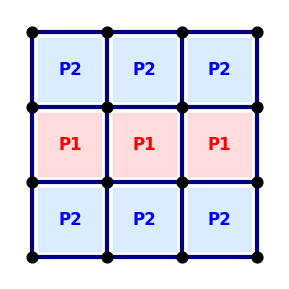

Tỷ số ô: P1 Simple(c=2) = 3 | P2 Strategic(c=3) = 6

=== TRẬN 2: Strategic (cutoff=3) đi trước vs Simple (cutoff=2) đi sau (lưới 3x3 ô) ===


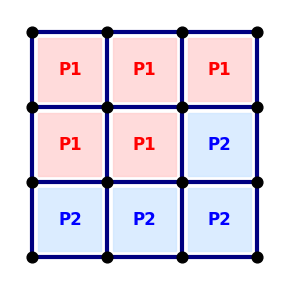

Tỷ số ô: P1 Strategic(c=3) = 5 | P2 Simple(c=2) = 4


In [19]:
def play_once_detail(p1, p2, size=(4, 4), show_board_end=True):
    """Cho 2 tác tử Heuristic (tất định) đấu 1 ván và trả về tỷ số ô."""
    b = empty_board(size)
    cur = 1
    while not terminal(b):
        move = p1(b, cur) if cur == 1 else p2(b, cur)
        prev = len(b['boxes'])
        b = result(b, cur, move)
        if len(b['boxes']) == prev:
            cur = -cur

    p1_boxes = sum(1 for v in b['boxes'].values() if v == 1)
    p2_boxes = sum(1 for v in b['boxes'].values() if v == -1)
    if show_board_end:
        show_board(b, figsize=(3.5, 3.5))
    return p1_boxes, p2_boxes

agent_simple_c2 = lambda b, p: heuristic_alpha_beta_search(b, player=p, cutoff=2, h_fn=h_simple)['move']
agent_strat_c3  = lambda b, p: heuristic_alpha_beta_search(b, player=p, cutoff=3, h_fn=h_strategic)['move']

print("=== TRẬN 1: Simple (cutoff=2) đi trước vs Strategic (cutoff=3) đi sau (lưới 3x3 ô) ===")
s1, s2 = play_once_detail(agent_simple_c2, agent_strat_c3, size=(4, 4))
print(f"Tỷ số ô: P1 Simple(c=2) = {s1} | P2 Strategic(c=3) = {s2}")

print("\n=== TRẬN 2: Strategic (cutoff=3) đi trước vs Simple (cutoff=2) đi sau (lưới 3x3 ô) ===")
s1, s2 = play_once_detail(agent_strat_c3, agent_simple_c2, size=(4, 4))
print(f"Tỷ số ô: P1 Strategic(c=3) = {s1} | P2 Simple(c=2) = {s2}")

## Tournament task [+1 to 5% bonus on your course grade; will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [19]:
# Your code/ answer goes here.

### Best First Move

How would you determine what the best first move for a standard board ($5 \times 5$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [20]:
# Your code/ answer goes here.